In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
sns.set()
import matplotlib.pyplot as plt

from sklearn import linear_model
import lightgbm as lgbm

from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold

In [3]:
X_train = pd.read_csv('../data/X_train.csv',index_col='ROW_ID')
X_test = pd.read_csv('../data/X_test.csv',index_col='ROW_ID')

y_train = pd.read_csv('../data/y_train.csv',index_col='ROW_ID')
sample_submission = pd.read_csv('../data/sample_submission.csv',index_col='ROW_ID')
total_data = pd.concat([X_train,y_train],axis=1)

In [4]:
from scipy import stats

def compute_bayesian_alloc_rate(train_targets, train_allocs, prior_strength=50):
    """
    Beta-Binomial posterior mean for each allocation's positive-rate.
    prior_strength (alpha0 + beta0) controls how much weight the prior carries,
    same role as 'k' in your earlier shrinkage estimator -- but here it's an
    explicit, principled Bayesian prior, not an ad-hoc formula.
    """
    global_rate = (np.sign(train_targets) > 0).mean()

    # prior: Beta(alpha0, beta0) centered on the global rate, with `prior_strength`
    # total pseudo-observations
    alpha0 = global_rate * prior_strength
    beta0 = (1 - global_rate) * prior_strength

    df = pd.DataFrame({'ALLOCATION': train_allocs, 'target': train_targets.values})
    grouped = df.groupby('ALLOCATION')['target']

    successes = grouped.apply(lambda s: (np.sign(s) > 0).sum())
    n = grouped.size()

    # posterior: Beta(alpha0 + successes, beta0 + failures)
    posterior_alpha = alpha0 + successes
    posterior_beta = beta0 + (n - successes)

    posterior_mean = posterior_alpha / (posterior_alpha + posterior_beta)

    # bonus: a genuine 90% credible interval per allocation, not just a point estimate
    ci_lower = stats.beta.ppf(0.05, posterior_alpha, posterior_beta)
    ci_upper = stats.beta.ppf(0.95, posterior_alpha, posterior_beta)

    return posterior_mean, ci_lower, ci_upper, global_rate

In [5]:
posterior_mean, ci_lower, ci_upper, global_rate = compute_bayesian_alloc_rate(
    total_data['target'], total_data['ALLOCATION'], prior_strength=51
)

summary = pd.DataFrame({
    'posterior_mean': posterior_mean,
    'ci_lower_90': ci_lower,
    'ci_upper_90': ci_upper,
}).sort_values('posterior_mean')

print(summary.head(5))   # your lowest allocations
print(summary.tail(5))   # your highest allocations

                posterior_mean  ci_lower_90  ci_upper_90
ALLOCATION                                              
ALLOCATION_111        0.387920     0.369675     0.406297
ALLOCATION_156        0.440509     0.424174     0.456897
ALLOCATION_86         0.443424     0.425106     0.461807
ALLOCATION_150        0.462071     0.443358     0.480829
ALLOCATION_257        0.462593     0.443879     0.481352
                posterior_mean  ci_lower_90  ci_upper_90
ALLOCATION                                              
ALLOCATION_118        0.582677     0.566388     0.598891
ALLOCATION_168        0.588227     0.569997     0.606356
ALLOCATION_187        0.614463     0.596419     0.632376
ALLOCATION_31         0.644839     0.626769     0.662736
ALLOCATION_152        0.655770     0.640040     0.671357


In [6]:
diff=summary["ci_upper_90"]-summary["ci_lower_90"]
print(diff.sort_values(ascending=False).head(5))  # your most uncertain allocations


ALLOCATION
ALLOCATION_46     0.195290
ALLOCATION_14     0.195290
ALLOCATION_109    0.042715
ALLOCATION_117    0.042715
ALLOCATION_167    0.042715
dtype: float64


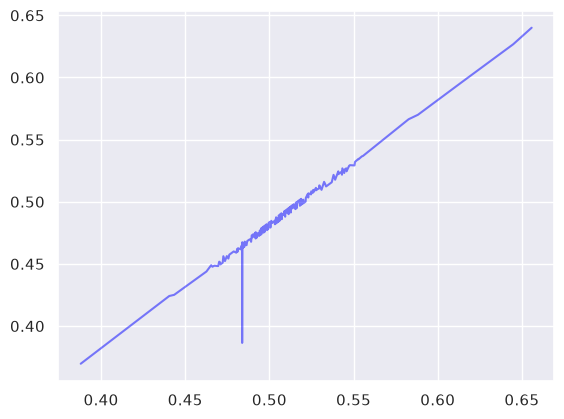

In [7]:
plt.plot(summary['posterior_mean'], summary['ci_lower_90'], color='blue', alpha=0.5)